# Review 1 — Classification Algorithms 1–5
**Dataset:** `HeartFailureDataset.csv` | **Target:** `cardio` (0 = no disease, 1 = disease)

Algorithms: Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, and SVC.

Place the CSV in the same folder as this notebook. Run cells from top to bottom. Uses an 80:20 stratified split and `random_state=42`.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay,
    RocCurveDisplay)
RANDOM_STATE = 42

## 2. Load and inspect dataset

In [2]:
df = pd.read_csv("HeartFailureDataset.csv")
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())
display(df.isnull().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())
display(df["cardio"].value_counts(dropna=False).to_frame("Target count"))

Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62,110,80,1,1,0,0,1,0
1,1,20228,1,156,85,140,90,3,1,0,0,1,1
2,2,18857,1,165,64,130,70,3,1,0,0,0,1
3,3,17623,2,169,82,150,100,1,1,0,0,1,1
4,4,17474,1,156,56,100,60,1,1,0,0,0,0


Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,Missing values
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


Duplicate rows: 0


,Target count
cardio,
0,35021
1,34979


## 3. Clean data and create features

In [3]:
df = df.drop_duplicates().dropna(subset=["cardio"]).copy()
if "age" in df.columns and df["age"].median() > 150:
    df["age_years"] = (df["age"] / 365.25).astype(int)
    df = df.drop(columns=["age"])
if {"height", "weight"}.issubset(df.columns):
    df["bmi"] = df["weight"] / (df["height"] / 100) ** 2
    df["bmi"] = df["bmi"].replace([np.inf, -np.inf], np.nan)
y = df["cardio"].astype(int)
X = df.drop(columns="cardio").select_dtypes(include=np.number).copy()
print("Rows:", len(df), "| Features:", X.shape[1])
print(X.columns.tolist())
display(X.head())

Rows: 70000 | Features: 13
['id', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi']


,id,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi
0,0,2,168,62,110,80,1,1,0,0,1,50,21.967120
1,1,1,156,85,140,90,3,1,0,0,1,55,34.927679
2,2,1,165,64,130,70,3,1,0,0,0,51,23.507805
3,3,2,169,82,150,100,1,1,0,0,1,48,28.710479
4,4,1,156,56,100,60,1,1,0,0,0,47,23.011177


## 4. Exploratory data analysis

In [ ]:
y.value_counts().sort_index().plot(kind="bar", edgecolor="black")
plt.title("Target Class Distribution")
plt.xlabel("cardio (0 = no disease, 1 = disease)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(X.describe().T)
X.hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions Before Outlier Treatment", y=1.02)
plt.tight_layout()
plt.show()

## 5. Split into training and testing data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("Proportion"))

Train: (56000, 13) | Test: (14000, 13)
Train class proportions:


,Proportion
cardio,
0,0.500304
1,0.499696


## 6. Missing values and outlier treatment

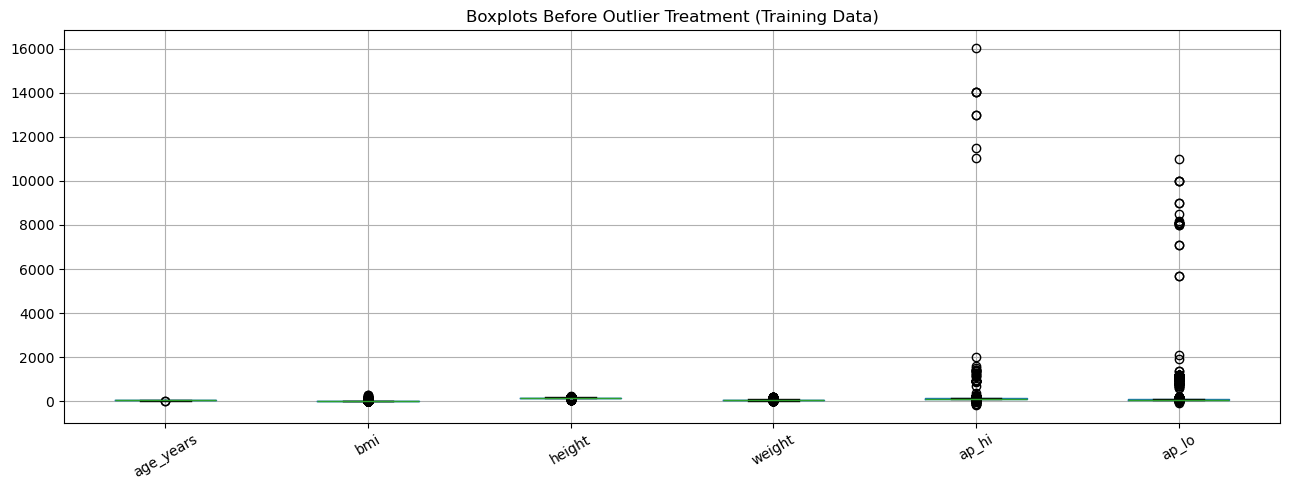

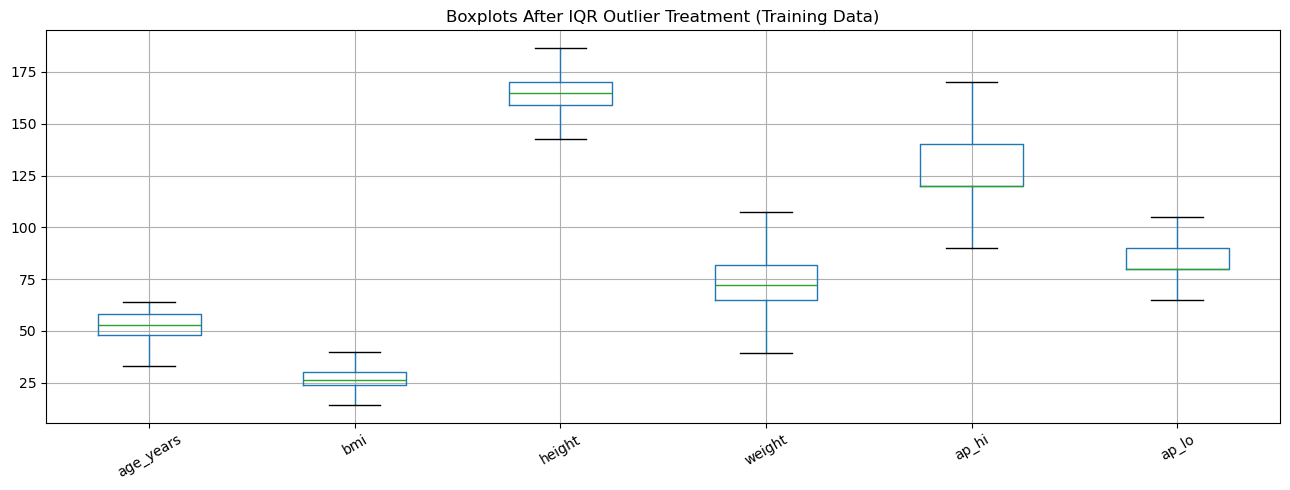

Remaining missing values: 0 0


In [5]:
# Fit imputer on training data only
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

cols = [c for c in ["age_years", "bmi", "height", "weight", "ap_hi", "ap_lo"] if c in X_train.columns]
if not cols:
    cols = X_train.columns[:min(6, len(X_train.columns))].tolist()

X_train[cols].boxplot(figsize=(13, 5), rot=30)
plt.title("Boxplots Before Outlier Treatment (Training Data)")
plt.tight_layout()
plt.show()

# IQR bounds learned from training data, then applied to train and test
for c in cols:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    X_train[c] = X_train[c].clip(low, high)
    X_test[c] = X_test[c].clip(low, high)

X_train[cols].boxplot(figsize=(13, 5), rot=30)
plt.title("Boxplots After IQR Outlier Treatment (Training Data)")
plt.tight_layout()
plt.show()
print("Remaining missing values:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

## 7. Scale features

In [6]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("Scaling complete.")

Scaling complete.


## 8. Algorithm 1 — Logistic Regression

In [7]:
model1 = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model1.fit(X_train_scaled, y_train)
pred1 = model1.predict(X_test_scaled)
score1 = model1.predict_proba(X_test_scaled)[:, 1]
print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, pred1), 4))
print("Weighted Precision:", round(precision_score(y_test, pred1, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, pred1, average="weighted", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, pred1, average="weighted", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, score1), 4))
print(classification_report(y_test, pred1, zero_division=0))

Logistic Regression
Accuracy: 0.7251
Weighted Precision: 0.7273
Weighted Recall: 0.7251
Weighted F1: 0.7244
ROC-AUC: 0.7876
              precision    recall  f1-score   support

           0       0.70      0.77      0.74      7004
           1       0.75      0.68      0.71      6996

    accuracy                           0.73     14000
   macro avg       0.73      0.73      0.72     14000
weighted avg       0.73      0.73      0.72     14000



## 9. Algorithm 2 — K-Nearest Neighbors (KNN)

In [8]:
model2 = KNeighborsClassifier(n_neighbors=5)
model2.fit(X_train_scaled, y_train)
pred2 = model2.predict(X_test_scaled)
score2 = model2.predict_proba(X_test_scaled)[:, 1]
print("KNN")
print("Accuracy:", round(accuracy_score(y_test, pred2), 4))
print("Weighted Precision:", round(precision_score(y_test, pred2, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, pred2, average="weighted", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, pred2, average="weighted", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, score2), 4))
print(classification_report(y_test, pred2, zero_division=0))

KNN
Accuracy: 0.6949
Weighted Precision: 0.695
Weighted Recall: 0.6949
Weighted F1: 0.6948
ROC-AUC: 0.7423
              precision    recall  f1-score   support

           0       0.69      0.71      0.70      7004
           1       0.70      0.68      0.69      6996

    accuracy                           0.69     14000
   macro avg       0.69      0.69      0.69     14000
weighted avg       0.69      0.69      0.69     14000



## 10. Algorithm 3 — Gaussian Naive Bayes

In [9]:
model3 = GaussianNB()
model3.fit(X_train_scaled, y_train)
pred3 = model3.predict(X_test_scaled)
score3 = model3.predict_proba(X_test_scaled)[:, 1]
print("Gaussian Naive Bayes")
print("Accuracy:", round(accuracy_score(y_test, pred3), 4))
print("Weighted Precision:", round(precision_score(y_test, pred3, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, pred3, average="weighted", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, pred3, average="weighted", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, score3), 4))
print(classification_report(y_test, pred3, zero_division=0))

Gaussian Naive Bayes
Accuracy: 0.7054
Weighted Precision: 0.7116
Weighted Recall: 0.7054
Weighted F1: 0.7033
ROC-AUC: 0.7713
              precision    recall  f1-score   support

           0       0.68      0.79      0.73      7004
           1       0.75      0.62      0.68      6996

    accuracy                           0.71     14000
   macro avg       0.71      0.71      0.70     14000
weighted avg       0.71      0.71      0.70     14000



## 11. Algorithm 4 — Decision Tree

In [10]:
model4 = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
model4.fit(X_train, y_train)
pred4 = model4.predict(X_test)
score4 = model4.predict_proba(X_test)[:, 1]
print("Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, pred4), 4))
print("Weighted Precision:", round(precision_score(y_test, pred4, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, pred4, average="weighted", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, pred4, average="weighted", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, score4), 4))
print(classification_report(y_test, pred4, zero_division=0))

Decision Tree
Accuracy: 0.7236
Weighted Precision: 0.7243
Weighted Recall: 0.7236
Weighted F1: 0.7233
ROC-AUC: 0.78
              precision    recall  f1-score   support

           0       0.71      0.75      0.73      7004
           1       0.74      0.69      0.72      6996

    accuracy                           0.72     14000
   macro avg       0.72      0.72      0.72     14000
weighted avg       0.72      0.72      0.72     14000



## 12. Algorithm 5 — Support Vector Classifier (SVC)

In [ ]:
# Linear kernel is used for practical runtime on this large dataset.
model5 = SVC(kernel="linear", random_state=RANDOM_STATE)
model5.fit(X_train_scaled, y_train)
pred5 = model5.predict(X_test_scaled)
score5 = model5.decision_function(X_test_scaled)
print("Support Vector Classifier (SVC)")
print("Accuracy:", round(accuracy_score(y_test, pred5), 4))
print("Weighted Precision:", round(precision_score(y_test, pred5, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, pred5, average="weighted", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, pred5, average="weighted", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, score5), 4))
print(classification_report(y_test, pred5, zero_division=0))

## 13. Confusion matrices

In [ ]:
predictions = {
    "Logistic Regression": pred1, "KNN": pred2, "Gaussian NB": pred3,
    "Decision Tree": pred4, "SVC": pred5
}
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, values_format="d")
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

## 14. ROC curves

In [ ]:
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, score1, name="Logistic Regression")
RocCurveDisplay.from_predictions(y_test, score2, name="KNN")
RocCurveDisplay.from_predictions(y_test, score3, name="Gaussian Naive Bayes")
RocCurveDisplay.from_predictions(y_test, score4, name="Decision Tree")
RocCurveDisplay.from_predictions(y_test, score5, name="SVC")
plt.title("ROC Curves — Classification Algorithms 1–5")
plt.tight_layout()
plt.show()

## 15. Comparison table

In [ ]:
results = []
for name, pred, score in [
    ("Logistic Regression", pred1, score1), ("KNN", pred2, score2),
    ("Gaussian Naive Bayes", pred3, score3), ("Decision Tree", pred4, score4),
    ("SVC", pred5, score5)
]:
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (weighted)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, score)
    })
comparison = pd.DataFrame(results).sort_values("F1-score (weighted)", ascending=False)
display(comparison.round(4))

## 16. Short explanation for presentation

- **Logistic Regression:** estimates the probability of a class using a logistic function.
- **KNN:** predicts based on the classes of the nearest training examples.
- **Gaussian Naive Bayes:** uses Bayes' theorem and assumes features are conditionally independent with Gaussian distributions.
- **Decision Tree:** makes predictions using a series of feature-based rules.
- **SVC:** finds a decision boundary that separates classes with a large margin.
- **Accuracy:** proportion of predictions that are correct.
- **Weighted Precision / Recall / F1:** metrics that account for the number of examples in each class.
- **Confusion matrix:** shows correct and incorrect predictions.
- **ROC-AUC:** measures how well a model separates the two classes.

**Runtime note:** KNN and SVC can take longer than the other algorithms. This notebook uses a linear SVC to keep training more practical. Preprocessing parameters are learned from training data only to reduce data leakage.